# H10：T+3 / T+5 终点日最高价标签研究

本 Notebook 保存 [研究卷宗 H10](README.md#h10) 的执行事实；研究结论由该段拥有。
保持 H08 固定划分方法、7/39列特征及模型参数，分别学习 T+3、T+5 **当天**最高价收益前10%事件。
T+1仅作为精确恢复锚点。最高价为监督参考，不表示可成交退出；全部预测日期已用于历史研究。

## 运行事实摘要

已完成六次固定拟合（T+1恢复锚点两次，T+3/T+5新增四次），两个T+1模型的439,970条预测精确复现。

| 期限 | 阶段 | 日频命中率 | 日频+L2命中率 | 增量（百分点） | 双侧95%名义区间（百分点） |
|---|---|---:|---:|---:|---|
| T+3 | 验证27日 | 21.15% | 25.03% | +3.88 | [-0.59, +8.43] |
| T+3 | 评估17日 | 28.71% | 25.76% | -2.94 | [-5.65, +0.35] |
| T+5 | 验证27日 | 18.59% | 21.17% | +2.58 | [-1.20, +6.75] |
| T+5 | 评估17日 | 25.65% | 24.94% | -0.71 | [-3.53, +2.82] |

T+3/T+5两段共同的预设探索性关注条件均未通过，含两期限校正的条件也未通过。
核验包括151日T+1标签、924份方法日名单和指标，以及六模型1,319,910条预测重载。
全部9个代码单元已顺序执行，图表随后仅做展示调整；没有新增独立预测日期或可实现收益验证。
完整解释与下一步由[卷宗H10](README.md#h10)维护。

## 1. 冻结方法与环境

[执行前冻结方案](/home/wsw/app/research-evidence/subscription-horizons-2026-10-08-mhbp58xm/protocol.json)
固定六次拟合、两种新增期限和停止条件。日频/L2在每个期限内使用相同训练行、候选池和权重。
验证为2026-07-17至08-24（27日），历史评估为08-26至09-17（17日）。

### 关键假设

P日特征和资格假设22:00可用，T 09:00选池，T+H 22:00标签成熟。没有实际历史接收日志。
按成熟时间，T+1/3/5各拟合106/104/102日，不能把不同期限间的全部表现差异只归因于标签。
T+H表示正式交易日偏移；标签取终点当天最高价，不能替换为期间最高价。
五日循环区块与此前方法相同；较长期限收益重叠，所得区间只作有限历史样本的名义诊断。

原08-25间隔保留；T+3/T+5验证尾部标签在评估开始后才成熟。由于没有基于验证选择或重拟合，本轮仅作同一冻结模型的两段诊断，不能当作先调参、再独立最终测试的流程。


In [1]:
from pathlib import Path
from datetime import date, time
from dataclasses import asdict
import hashlib
import importlib.metadata
import json
import math
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from scipy.stats import rankdata
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score, brier_score_loss
from threadpoolctl import threadpool_limits
from IPython.display import display, Image

evidence = Path("/home/wsw/app/research-evidence/subscription-horizons-2026-10-08-mhbp58xm")
sys.path.insert(0, str(evidence / "runtime-source"))
from src.config.model_config import PreprocessingConfig
from src.data_system.builders.stock_1430 import _label_window_vwap, _positive_ratio
from src.training.engines.preprocessing import FittedPreprocessor
from src.training.inference_model import InferenceModel
from src.training.top_selection import select_top_symbols, evaluate_top_selection
from src.utils.datetime_utils import DateTimeUtils
from src.utils.price_utils import apply_asof_price_adjustment
from src.utils.parquet_writer import write_parquet_atomic

protocol = json.loads((evidence / "protocol.json").read_text())
assert hashlib.sha256((evidence / "protocol.json").read_bytes()).hexdigest() == "6c79f05539bd3993399d55c90f7e7e9688929df371e5b75cce80c339de25ff97"
versions = json.loads((evidence / "environment.json").read_text())
for package, version in versions["packages"].items():
    assert importlib.metadata.version(package) == version, package
for directory in ("models", "predictions", "labels", "figures"):
    (evidence / directory).mkdir(exist_ok=True)
keys = ["symbol", "trade_date", "decision_ts_utc"]
fixed = evidence / "inputs/fixed"
print("Frozen:", protocol["frozen_at"], "| baseline:", protocol["base_commit"])
print("Model:", protocol["model"], protocol["model_params"])


Frozen: 2026-10-08T09:46:55.177012+08:00 | baseline: 76c25a279685b6961cda69143f542e8ec3936f51
Model: HistGradientBoostingClassifier {'max_iter': 100, 'max_leaf_nodes': 7, 'max_depth': 3, 'min_samples_leaf': 500, 'learning_rate': 0.05, 'l2_regularization': 10, 'max_bins': 63, 'early_stopping': False, 'random_state': 20260919}


## 2. 输入、日历与原特征

只读隔离副本。逐文件验证冻结清单，原价格充分输入来自 H06，额外终点分钟来自09-21至09-24。
原T日 universe 用于标签排名；原P日合格 universe 用于拟合和预测，二者不会按未来标签合并筛选。


In [2]:
input_manifest = json.loads((evidence / "input-manifest.json").read_text())
source_manifest = json.loads((evidence / "source-manifest.json").read_text())
for record in input_manifest:
    path = evidence / record["path"]
    assert path.stat().st_size == record["size_bytes"], record["path"]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == record["sha256"], record["path"]
for relative, record in source_manifest.items():
    path = evidence / "runtime-source" / relative
    assert hashlib.sha256(path.read_bytes()).hexdigest() == record["sha256"], relative
calendar = pd.read_parquet(fixed / "processed/trade_calendar/v1/year=2026/data.parquet")
sessions = sorted(calendar.loc[calendar.is_open, "trade_date"].tolist())
session_positions = {day: i for i, day in enumerate(sessions)}
target_days = sorted(protocol["plans"]["1"]["exit_dates"])
features_by_day = {}
for day in target_days:
    frame = pd.read_parquet(fixed / f"features/previous_day_daily_l2/v1/trade_date={day}/data.parquet")
    assert not frame.duplicated(keys).any()
    assert frame.trade_date.eq(day).all()
    assert frame.source_date.eq(sessions[session_positions[day] - 1]).all()
    assert frame.feature_ready_ts.lt(frame.decision_ts_utc).all()
    features_by_day[day] = frame
features = pd.concat(features_by_day.values(), ignore_index=True)
feature_digest = hashlib.sha256(pd.util.hash_pandas_object(features, index=True).to_numpy().tobytes()).hexdigest()
universe = pd.read_parquet(evidence / "inputs/h06/candidate-labels.parquet", columns=["symbol", "trade_date"])
universe = universe.loc[universe.trade_date.isin(target_days)]
assert not universe.duplicated(["symbol", "trade_date"]).any()
universe_by_day = {day: group.symbol.reset_index(drop=True) for day, group in universe.groupby("trade_date", sort=True)}
assert set(universe_by_day) == set(target_days)
print({"input_files": len(input_manifest), "source_files": len(source_manifest), "target_days": len(target_days),
       "eligible_feature_rows": len(features), "feature_sha256": feature_digest})
display(pd.DataFrame([{"horizon": int(h), "fit_days": len(p["train_dates"]), "fit_last": p["train_dates"][-1],
                       "purged_days": len(p["purged_dates"]), "last_exit": p["exit_dates"][target_days[-1]]}
                      for h, p in protocol["plans"].items()]))


{'input_files': 1047, 'source_files': 169, 'target_days': 151, 'eligible_feature_rows': 753258, 'feature_sha256': '9086fe2e6ba6476c2a3c22a49c3c654bea4e797e9b763d71774120262bd2b13e'}


,horizon,fit_days,fit_last,purged_days,last_exit
0,1,106,2026-07-15,1,2026-09-18
1,3,104,2026-07-13,3,2026-09-22
2,5,102,2026-07-09,5,2026-09-24


## 3. 补充终点价格与独立核验

复用原 H06 的逐日后复权入场VWAP和全日最高价。09-21至09-24只补足较长期限的终点价格；
不扩展预测日期或改变特征。新增分钟的全天高点与Pandas分组最大值独立核对，入场窗口与整数成交量求和交叉检查。


In [3]:
old_prices = pd.read_parquet(evidence / "inputs/h06/daily-prices.parquet")
assert not old_prices.duplicated(["trade_date", "symbol"]).any()
price_parts = [old_prices]
extra_price_checks = []
for day in ["2026-09-21", "2026-09-22", "2026-09-23", "2026-09-24"]:
    tables = []
    for dataset in ("sh_stock_trade_1m", "sz_stock_trade_1m"):
        path = evidence / "inputs/additional/processed" / dataset / "v1" / f"trade_date={day}/data.parquet"
        tables.append(pq.ParquetFile(path).read(columns=["symbol", "trade_date", "minute_start_ts_utc", "phase", "high", "notional_sum", "volume_sum"]))
    minutes = pa.concat_tables(tables)
    minute_frame = minutes.to_pandas()
    assert not minute_frame.duplicated(["symbol", "trade_date", "minute_start_ts_utc", "phase"]).any()
    assert minute_frame.trade_date.eq(day).all() and minute_frame.phase.isin([0, 2]).all()
    high = minutes.select(["symbol", "high"]).group_by("symbol", use_threads=False).aggregate([("high", "max")]).to_pandas().set_index("symbol").high_max
    pd.testing.assert_series_equal(high.sort_index(), minute_frame.groupby("symbol").high.max().sort_index(), check_names=False)
    entry = _label_window_vwap(minutes, trade_date=date.fromisoformat(day))
    start = DateTimeUtils.local_time_to_utc_epoch_us(time(14, 31), date.fromisoformat(day))
    end = DateTimeUtils.local_time_to_utc_epoch_us(time(14, 36), date.fromisoformat(day))
    chosen = minute_frame.loc[minute_frame.phase.eq(2) & minute_frame.minute_start_ts_utc.ge(start) & minute_frame.minute_start_ts_utc.lt(end)]
    volume = chosen.assign(volume_sum=chosen.volume_sum.astype(object)).groupby("symbol").volume_sum.sum()
    independent_entry = chosen.groupby("symbol").notional_sum.sum() / volume.astype(float)
    np.testing.assert_allclose(entry.reindex(independent_entry.index), independent_entry, rtol=1e-14, atol=0)
    factors = pd.read_parquet(evidence / f"inputs/additional/processed/adj_factor/v1/trade_date={day}/data.parquet")
    assert not factors.duplicated("symbol").any() and factors.trade_date.eq(day).all()
    frame = pd.DataFrame({"raw_high": high, "raw_window": entry})
    frame["adj_factor"] = factors.set_index("symbol").adj_factor.reindex(frame.index)
    prices = apply_asof_price_adjustment(frame, adjustment="hfq", asof_date=day,
                                        price_columns=("raw_high", "raw_window"), output_prefix="adjusted_")
    prices = prices.reset_index().assign(trade_date=day)
    price_parts.append(prices)
    extra_price_checks.append({"trade_date": day, "minute_rows": len(minutes), "symbols": len(prices)})
prices = pd.concat(price_parts, ignore_index=True)
assert not prices.duplicated(["trade_date", "symbol"]).any()
prices_by_day = {day: frame.set_index("symbol") for day, frame in prices.groupby("trade_date", sort=True)}
required_price_days = set(target_days)
for plan in protocol["plans"].values():
    required_price_days.update(plan["exit_dates"].values())
assert required_price_days <= set(prices_by_day)
write_parquet_atomic(output_file=evidence / "daily-prices.parquet", table=pa.Table.from_pandas(prices.loc[prices.trade_date.isin(required_price_days)], preserve_index=False))
display(pd.DataFrame(extra_price_checks))
del minutes, minute_frame, tables, chosen, old_prices, price_parts


,trade_date,minute_rows,symbols
0,2026-09-21,1224658,5208
1,2026-09-22,1221947,5208
2,2026-09-23,1219215,5209
3,2026-09-24,1219933,5209


## 4. 标签、成熟边界与T+1恢复

先在原T日 universe 计算调整后收益和横截面排名，再连接到冻结特征的P日合格股票池。
缺失标签在拟合中剔除，在推理中保留，评价名单固定后才调整有效分母。
边界场景覆盖交易日/节假日、终点日而非期间高点、复权、并列、严格0.9、缺失与标签成熟。


In [4]:
def _endpoint_labels(symbols: pd.Series, entry: pd.DataFrame, endpoint: pd.DataFrame) -> pd.DataFrame:
    adjusted_entry = symbols.map(entry.adjusted_raw_window)
    adjusted_exit = symbols.map(endpoint.adjusted_raw_high)
    returns = _positive_ratio(adjusted_exit, adjusted_entry) - 1
    ranks = returns.rank(method="average", pct=True)
    return pd.DataFrame({"symbol": symbols.to_numpy(), "entry_adjusted": adjusted_entry.to_numpy(),
                         "exit_adjusted": adjusted_exit.to_numpy(), "return": returns.to_numpy(),
                         "y_rank_return": ranks.to_numpy(), "y_event": ranks.gt(0.9).astype(float).where(ranks.notna()).to_numpy()})

fixture_symbols = pd.Series(["a", "b", "c", "missing"])
fixture_entry = pd.DataFrame({"adjusted_raw_window": [10.0, 10.0, 10.0]}, index=["a", "b", "c"])
fixture_exit = pd.DataFrame({"adjusted_raw_high": [12.0, 12.0, 11.0]}, index=["a", "b", "c"])
fixture_result = _endpoint_labels(fixture_symbols, fixture_entry, fixture_exit)
np.testing.assert_allclose(fixture_result.y_rank_return.iloc[:3], [5/6, 5/6, 1/3])
assert fixture_result.y_rank_return.isna().tolist() == [False, False, False, True]
assert fixture_result.y_event.iloc[:3].eq(0).all()
assert pd.Series(np.arange(10)).rank(pct=True).gt(0.9).sum() == 1
assert not pd.Series([0.9]).gt(0.9).iloc[0]
# 当天高点12不能替换为中间某天的20；缺终点不延后到复牌日。
assert fixture_result.exit_adjusted.iloc[0] == 12 and fixture_result.exit_adjusted.iloc[0] != 20
missing_endpoint = fixture_exit.drop(index="a")
assert pd.isna(_endpoint_labels(fixture_symbols, fixture_entry, missing_endpoint).y_event.iloc[0])
adjusted_fixture = apply_asof_price_adjustment(pd.DataFrame({"raw_high": [6.0], "adj_factor": [2.0]}, index=["a"]),
                                             adjustment="hfq", asof_date="2026-09-22", price_columns=("raw_high",), output_prefix="adjusted_")
assert _endpoint_labels(pd.Series(["a"]), fixture_entry, adjusted_fixture).exit_adjusted.iloc[0] == 12
assert sessions[session_positions["2026-09-17"] + 3] == "2026-09-22"
assert sessions[session_positions["2026-09-17"] + 5] == "2026-09-24"
assert sessions[session_positions["2026-09-24"] + 1] == "2026-09-28"
labels_by_horizon = {}
label_profiles = []
label_anchor_days = 0
for horizon in protocol["horizons"]:
    parts = []
    plan = protocol["plans"][str(horizon)]
    for day in target_days:
        endpoint = sessions[session_positions[day] + horizon]
        assert endpoint == plan["exit_dates"][day]
        full = _endpoint_labels(universe_by_day[day], prices_by_day[day], prices_by_day[endpoint])
        valid = full["return"].notna()
        np.testing.assert_array_equal(full.loc[valid, "y_rank_return"], rankdata(full.loc[valid, "return"], method="average") / valid.sum())
        # 原始价格与各自日期因子直接计算，独立核对收益和有效集合。
        symbols = universe_by_day[day]
        entry_raw = symbols.map(prices_by_day[day].raw_window).to_numpy(dtype=float)
        entry_factor = symbols.map(prices_by_day[day].adj_factor).to_numpy(dtype=float)
        exit_raw = symbols.map(prices_by_day[endpoint].raw_high).to_numpy(dtype=float)
        exit_factor = symbols.map(prices_by_day[endpoint].adj_factor).to_numpy(dtype=float)
        valid_raw = np.isfinite(entry_raw) & (entry_raw > 0) & np.isfinite(entry_factor) & (entry_factor > 0) & np.isfinite(exit_raw) & (exit_raw > 0) & np.isfinite(exit_factor) & (exit_factor > 0)
        np.testing.assert_array_equal(valid.to_numpy(), valid_raw)
        independent = exit_raw[valid_raw] * exit_factor[valid_raw] / (entry_raw[valid_raw] * entry_factor[valid_raw]) - 1
        np.testing.assert_array_equal(full.loc[valid, "return"], independent)
        full["trade_date"] = day
        full["exit_date"] = endpoint
        full["label_ready_ts"] = DateTimeUtils.local_time_to_utc_epoch_us(time(22), date.fromisoformat(endpoint))
        aligned = features_by_day[day][keys].copy()
        full_by_symbol = full.set_index("symbol")
        for column in ["entry_adjusted", "exit_adjusted", "return", "y_rank_return", "y_event"]:
            aligned[column] = aligned.symbol.map(full_by_symbol[column])
        # T universe缺席时标签未知；日期和成熟时点仍由目标交易日唯一确定。
        aligned["exit_date"] = endpoint
        aligned["label_ready_ts"] = DateTimeUtils.local_time_to_utc_epoch_us(time(22), date.fromisoformat(endpoint))
        assert aligned[keys].equals(features_by_day[day][keys])
        assert aligned.y_event.isna().equals(aligned.y_rank_return.isna())
        if horizon == 1:
            for dataset, column in [("next_day_high_return_rank", "y_rank_return"), ("next_day_high_top_decile", "y_event")]:
                anchor = pd.read_parquet(fixed / f"labels/{dataset}/v1/trade_date={day}/data.parquet")
                assert anchor[keys].equals(aligned[keys])
                np.testing.assert_array_equal(aligned[column], anchor[column])
                np.testing.assert_array_equal(aligned.label_ready_ts, anchor.label_ready_ts)
            label_anchor_days += 1
        label_profiles.append({"horizon": horizon, "trade_date": day, "exit_date": endpoint,
                               "full_universe": len(full), "full_known": int(valid.sum()), "eligible": len(aligned),
                               "eligible_known": int(aligned.y_event.notna().sum()), "events": int(aligned.y_event.eq(1).sum())})
        parts.append(aligned)
    labels = pd.concat(parts, ignore_index=True)
    assert labels[keys].equals(features[keys])
    labels_by_horizon[horizon] = labels
    write_parquet_atomic(output_file=evidence / "labels" / f"t{horizon}.parquet", table=pa.Table.from_pandas(labels, preserve_index=False))
    first_decision = DateTimeUtils.local_time_to_utc_epoch_us(time(9), date.fromisoformat(plan["validation_dates"][0]))
    eligible_dates = [day for day in protocol["plans"]["1"]["train_dates"] + protocol["plans"]["1"]["purged_dates"]
                      if DateTimeUtils.local_time_to_utc_epoch_us(time(22), date.fromisoformat(plan["exit_dates"][day])) < first_decision]
    assert eligible_dates == plan["train_dates"]
    assert labels.loc[labels.trade_date.isin(plan["train_dates"]), "label_ready_ts"].lt(first_decision).all()
    assert labels.loc[labels.trade_date.isin(plan["purged_dates"]), "label_ready_ts"].ge(first_decision).all()
profile = pd.DataFrame(label_profiles)
profile.to_csv(evidence / "label-profile.csv", index=False)
assert label_anchor_days == 151
print("T+1 exact label recovery:", label_anchor_days, "days; formal-session and maturity boundaries passed.")
display(profile.groupby("horizon")[["eligible", "eligible_known", "events"]].sum())


T+1 exact label recovery: 151 days; formal-session and maturity boundaries passed.


,eligible,eligible_known,events
horizon,,,
1,753258,752754,75506
3,753258,752514,74833
5,753258,752322,74819


## 5. 六次固定拟合与全候选预测

按期限重新拟合相同分类器。预处理只接触已成熟且标签已知的拟合行；使用同一项目的
`FittedPreprocessor`与`InferenceModel`，填0.5、不缩放、日期等权。没有验证后重拟合或早停。
预测只接收原特征，保存完整名单候选分数后再读取评价标签。T+1逐日预测必须与原API制品精确相同。


In [5]:
prediction_features = features.loc[features.trade_date.isin(protocol["prediction_dates"])].reset_index(drop=True)
assert len(prediction_features) == 219985
predictions = {}
fit_records = []
anchor_prediction_rows = 0
for horizon in protocol["horizons"]:
    plan = protocol["plans"][str(horizon)]
    labels = labels_by_horizon[horizon]
    train_mask = features.trade_date.isin(plan["train_dates"]) & labels.y_event.notna()
    altered_target = labels.y_event.copy()
    altered_target.loc[labels.trade_date.isin(protocol["prediction_dates"])] = np.nan
    altered_train_mask = features.trade_date.isin(plan["train_dates"]) & altered_target.notna()
    np.testing.assert_array_equal(altered_train_mask, train_mask)
    np.testing.assert_array_equal(altered_target.loc[altered_train_mask], labels.loc[train_mask, "y_event"])
    fit_keys = features.loc[train_mask, keys].reset_index(drop=True)
    y = labels.loc[train_mask, "y_event"].reset_index(drop=True)
    counts = fit_keys.groupby("trade_date").symbol.transform("size")
    weights = 1.0 / counts.to_numpy(dtype=float)
    weights = weights / weights.mean()
    date_weight = pd.Series(weights).groupby(fit_keys.trade_date).sum()
    np.testing.assert_allclose(date_weight.to_numpy(), np.repeat(date_weight.iloc[0], len(date_weight)), rtol=1e-14, atol=0)
    write_parquet_atomic(output_file=evidence / "models" / f"fit-keys-t{horizon}.parquet",
                         table=pa.Table.from_pandas(fit_keys.assign(y_event=y, weight=weights), preserve_index=False))
    for method, columns in protocol["features"].items():
        train_X = features.loc[train_mask, columns].reset_index(drop=True)
        preprocess = FittedPreprocessor.fit(train_X=train_X, config=PreprocessingConfig.model_validate(protocol["preprocessing"]))
        keep, X = preprocess.transform(train_X.to_numpy(dtype=float))
        assert keep.all()
        np.testing.assert_array_equal(X, train_X.fillna(0.5).to_numpy(dtype=float))
        model = HistGradientBoostingClassifier(**protocol["model_params"])
        with threadpool_limits(limits=1), warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            model.fit(X, y.to_numpy(dtype=float), sample_weight=weights)
        assert model.n_iter_ == 100
        fitted = InferenceModel(model=model, preprocess=preprocess, feature_set="previous_day_daily_l2", feature_version="v1",
                                train_dates=tuple(plan["train_dates"]), label_set=f"research_h10_endpoint_high_t{horizon}",
                                label_version="draft", label_column="y_event", prediction_method="positive_probability")
        model_path = evidence / "models" / f"t{horizon}-{method}.joblib"
        joblib.dump(fitted, model_path)
        scores = fitted.predict(prediction_features[columns].to_numpy(dtype=float))
        assert np.isfinite(scores).all() and ((scores >= 0) & (scores <= 1)).all()
        prediction = prediction_features[keys].copy()
        prediction["prediction"] = scores
        prediction["stage"] = np.where(prediction.trade_date.isin(plan["validation_dates"]), "validation", "evaluation")
        predictions[(horizon, method)] = prediction
        write_parquet_atomic(output_file=evidence / "predictions" / f"t{horizon}-{method}.parquet",
                             table=pa.Table.from_pandas(prediction, preserve_index=False))
        if horizon == 1:
            for day, part in prediction.groupby("trade_date", sort=True):
                anchor = pd.read_parquet(evidence / "anchors" / method / "predictions" / f"{day}.parquet")
                assert part[keys].reset_index(drop=True).equals(anchor[keys])
                np.testing.assert_array_equal(part.prediction, anchor.prediction)
                anchor_prediction_rows += len(part)
        fit_records.append({"horizon": horizon, "method": method, "train_days": len(plan["train_dates"]),
                            "train_first": plan["train_dates"][0], "train_last": plan["train_dates"][-1],
                            "fit_rows": int(train_mask.sum()), "unknown_fit_labels": int((features.trade_date.isin(plan["train_dates"]) & labels.y_event.isna()).sum()),
                            "maximum_label_ready_ts": int(labels.loc[train_mask, "label_ready_ts"].max()),
                            "feature_columns": columns, "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(),
                            "prediction_rows": len(prediction)})
        (evidence / "fit-records.json").write_text(json.dumps(fit_records, ensure_ascii=False, indent=2))
        print(f"Fitted T+{horizon} {method}: {int(train_mask.sum()):,} rows, {len(plan['train_dates'])} days; predictions {len(prediction):,}", flush=True)
assert len(fit_records) == 6 and anchor_prediction_rows == 439970
assert hashlib.sha256(pd.util.hash_pandas_object(features, index=True).to_numpy().tobytes()).hexdigest() == feature_digest
print("Two T+1 models exactly reproduce all frozen predictions:", anchor_prediction_rows)


Fitted T+1 daily7: 527,875 rows, 106 days; predictions 219,985
Fitted T+1 all39: 527,875 rows, 106 days; predictions 219,985
Fitted T+3 daily7: 517,742 rows, 104 days; predictions 219,985
Fitted T+3 all39: 517,742 rows, 104 days; predictions 219,985
Fitted T+5 daily7: 507,655 rows, 102 days; predictions 219,985
Fitted T+5 all39: 507,655 rows, 102 days; predictions 219,985
Two T+1 models exactly reproduce all frozen predictions: 439970


## 6. 固定名单评价与独立计数

复用既有名单和评价函数，随后用NumPy排序与事件列独立恢复全部名单、分子和分母。
两模型与五规则都保留；随机基准使用各期限当日有效候选池的事件比例。


In [6]:
metric_rows = []
selection_rows = []
diagnostic_rows = []
independent_method_days = 0
for horizon in protocol["horizons"]:
    label_days = {day: frame.reset_index(drop=True) for day, frame in labels_by_horizon[horizon].groupby("trade_date", sort=True)}
    prediction_days = {method: {day: frame.reset_index(drop=True) for day, frame in predictions[(horizon, method)].groupby("trade_date", sort=True)}
                       for method in protocol["features"]}
    for day in protocol["prediction_dates"]:
        feature_day = features_by_day[day]
        labels = label_days[day]
        assert feature_day[keys].equals(labels[keys])
        stage = "validation" if day in protocol["plans"][str(horizon)]["validation_dates"] else "evaluation"
        symbols = feature_day.symbol.to_numpy(dtype=str)
        scores = {method: prediction_days[method][day].prediction.to_numpy(dtype=float) for method in protocol["features"]}
        scores.update({method: feature_day[column].to_numpy(dtype=float) for method, column in protocol["rules"].items()})
        frozen_positions = {method: select_top_symbols(symbols, score, top_k=50) for method, score in scores.items()}
        ranks = labels.y_rank_return.to_numpy(dtype=float)
        for method, score in scores.items():
            positions = frozen_positions[method]
            row = {"horizon": horizon, "stage": stage, "trade_date": day, "method": method,
                   **asdict(evaluate_top_selection(ranks=ranks, selected=positions))}
            independent_positions = np.lexsort((symbols, np.where(np.isfinite(score), -score, np.inf)))[:50]
            np.testing.assert_array_equal(positions, independent_positions)
            known = labels.y_event.notna().to_numpy()
            positive = labels.y_event.eq(1).to_numpy()
            selected_mask = np.zeros(len(labels), dtype=bool)
            selected_mask[independent_positions] = True
            hits = int((positive & selected_mask).sum())
            selected_known = int((known & selected_mask).sum())
            pool_known = int(known.sum())
            opportunities = int(positive.sum())
            assert row["hits"] == hits and row["selected_known"] == selected_known and row["opportunities"] == opportunities
            assert row["precision"] == (hits / selected_known if selected_known else None)
            assert row["recall"] == (hits / opportunities if opportunities else None)
            assert row["f1"] == (2 * hits / (selected_known + opportunities) if selected_known + opportunities else None)
            assert row["random_precision"] == opportunities / pool_known
            assert row["lift"] == (hits / selected_known) / (opportunities / pool_known)
            assert row["unknown_selected"] == 50 - selected_known
            if horizon == 1:
                anchor_method = "model" if method in protocol["features"] else method
                anchor_root = evidence / "anchors" / (method if method in protocol["features"] else "all39")
                anchor_metrics = pd.read_parquet(anchor_root / "selection-metrics.parquet")
                anchor_row = anchor_metrics.loc[anchor_metrics.stage.eq(stage) & anchor_metrics.trade_date.eq(day) & anchor_metrics.method.eq(anchor_method)].iloc[0]
                for field in asdict(evaluate_top_selection(ranks=ranks, selected=positions)):
                    assert row[field] == anchor_row[field], (day, method, field)
            metric_rows.append(row)
            selection_rows.append({"horizon": horizon, "stage": stage, "trade_date": day, "method": method, "symbols": symbols[positions].tolist()})
            independent_method_days += 1
            if method in protocol["features"]:
                diagnostic_rows.append({"horizon": horizon, "stage": stage, "trade_date": day, "method": method,
                                        "auc": roc_auc_score(positive[known], score[known]),
                                        "brier": brier_score_loss(positive[known], score[known]),
                                        "selected_mean_probability": float(score[positions][known[positions]].mean())})
metrics = pd.DataFrame(metric_rows)
selections = pd.DataFrame(selection_rows)
diagnostics = pd.DataFrame(diagnostic_rows)
assert independent_method_days == 924
assert metrics.precision.notna().all() and metrics.groupby(["horizon", "stage", "method"]).size().isin([27, 17]).all()
summary = metrics.groupby(["horizon", "stage", "method"], sort=False).agg(
    days=("trade_date", "size"), hits=("hits", "sum"), selected_known=("selected_known", "sum"),
    unknown_selected=("unknown_selected", "sum"), precision=("precision", "mean"), recall=("recall", "mean"),
    f1=("f1", "mean"), lift=("lift", "mean"), random_precision=("random_precision", "mean"),
    selection_coverage=("selection_coverage", "mean"), pool_coverage=("pool_coverage", "mean"),
).reset_index()
for name, frame in [("daily-metrics", metrics), ("selections", selections)]:
    write_parquet_atomic(output_file=evidence / f"{name}.parquet", table=pa.Table.from_pandas(frame, preserve_index=False))
summary.to_csv(evidence / "summary.csv", index=False)
diagnostics.to_csv(evidence / "probability-diagnostics.csv", index=False)
display(summary.loc[summary.method.isin(["daily7", "all39", "rule_volatility"]),
                    ["horizon", "stage", "method", "days", "precision", "hits", "selected_known", "unknown_selected", "lift"]].round(6))


,horizon,stage,method,days,precision,hits,selected_known,unknown_selected,lift
0,1,validation,daily7,27,0.320484,432,1348,2,3.228068
1,1,validation,all39,27,0.331247,446,1346,4,3.332821
5,1,validation,rule_volatility,27,0.360000,486,1350,0,3.595600
7,1,evaluation,daily7,17,0.376423,319,848,2,3.798003
8,1,evaluation,all39,17,0.399352,339,849,1,4.032104
12,1,evaluation,rule_volatility,17,0.307347,261,848,2,3.083866
14,3,validation,daily7,27,0.211459,285,1349,1,2.125370
15,3,validation,all39,27,0.250295,337,1348,2,2.499773
19,3,validation,rule_volatility,27,0.305185,412,1350,0,3.030286
21,3,evaluation,daily7,17,0.287059,244,850,0,2.896016


## 7. 配对增量与不确定性

固定5日循环区块、20,000次重采样、seed=20261007。两段分别计算，差值为39列减7列。
保留双侧95%区间及单侧95%下界；两个新增期限另列Bonferroni单侧97.5%下界，不据此挑选历史赢家。
同时达到两段均值增量≥2个百分点和下界>0，才满足相应探索性关注条件。全部结果均非独立确认。


In [7]:
paired = metrics.loc[metrics.method.isin(protocol["features"])].pivot(index=["horizon", "stage", "trade_date"], columns="method", values="precision")
paired["difference"] = paired.all39 - paired.daily7
comparison_rows = []
for horizon in protocol["horizons"]:
    for stage in ["validation", "evaluation"]:
        values = paired.xs((horizon, stage)).difference.to_numpy()
        settings = protocol["uncertainty"]
        rng = np.random.default_rng(settings["seed"])
        starts = rng.integers(0, len(values), size=(settings["resamples"], math.ceil(len(values) / settings["block_sessions"])))
        indices = (starts[..., None] + np.arange(settings["block_sessions"])) % len(values)
        indices = indices.reshape(settings["resamples"], -1)[:, :len(values)]
        means = values[indices].mean(axis=1)
        # 循环拼接与向量化索引独立交叉检查固定的前25次重采样。
        for iteration in range(25):
            independent_indices = []
            for start in starts[iteration]:
                independent_indices.extend((int(start) + offset) % len(values) for offset in range(5))
            assert float(values[independent_indices[:len(values)]].mean()) == means[iteration]
        low, high = np.quantile(means, [0.025, 0.975])
        one_sided = float(np.quantile(means, 0.05))
        comparison_rows.append({"horizon": horizon, "stage": stage, "days": len(values),
                                "mean_difference": float(values.mean()), "ci95_lower": float(low), "ci95_upper": float(high),
                                "one_sided95_lower": one_sided, "two_horizon_adjusted_lower": float(low),
                                "wins": int((values > 0).sum()), "ties": int((values == 0).sum()), "losses": int((values < 0).sum()),
                                "nominal_criterion_met": bool(values.mean() >= 0.02 and one_sided > 0),
                                "adjusted_criterion_met": bool(values.mean() >= 0.02 and low > 0)})
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(evidence / "paired-comparison.csv", index=False)
paired.to_csv(evidence / "paired-daily.csv")
display(comparison.round(6))
print("Both-period criteria:")
display(comparison.groupby("horizon")[["nominal_criterion_met", "adjusted_criterion_met"]].all())


Both-period criteria:


,horizon,stage,days,mean_difference,ci95_lower,ci95_upper,one_sided95_lower,two_horizon_adjusted_lower,wins,ties,losses,nominal_criterion_met,adjusted_criterion_met
0,1,validation,27,0.010763,-0.001421,0.024611,0.000227,-0.001421,12,5,10,False,False
1,1,evaluation,17,0.022929,0.012941,0.034118,0.014166,0.012941,9,3,5,True,True
2,3,validation,27,0.038836,-0.005926,0.084339,0.000741,-0.005926,15,1,11,True,False
3,3,evaluation,17,-0.029412,-0.056471,0.003529,-0.052941,-0.056471,5,2,10,False,False
4,5,validation,27,0.025790,-0.011988,0.067483,-0.006667,-0.011988,15,2,10,False,False
5,5,evaluation,17,-0.007059,-0.035294,0.028235,-0.032941,-0.035294,6,2,9,False,False


,nominal_criterion_met,adjusted_criterion_met
horizon,,
1,False,False
3,False,False
5,False,False


## 8. 结果图

左图比较相同期限内两模型与高波动率规则；右图为配对增量及双侧95%名义区间。
不同期限预测的是不同事件，绝对命中率不用于选择最优持有期，也不表示收益率。


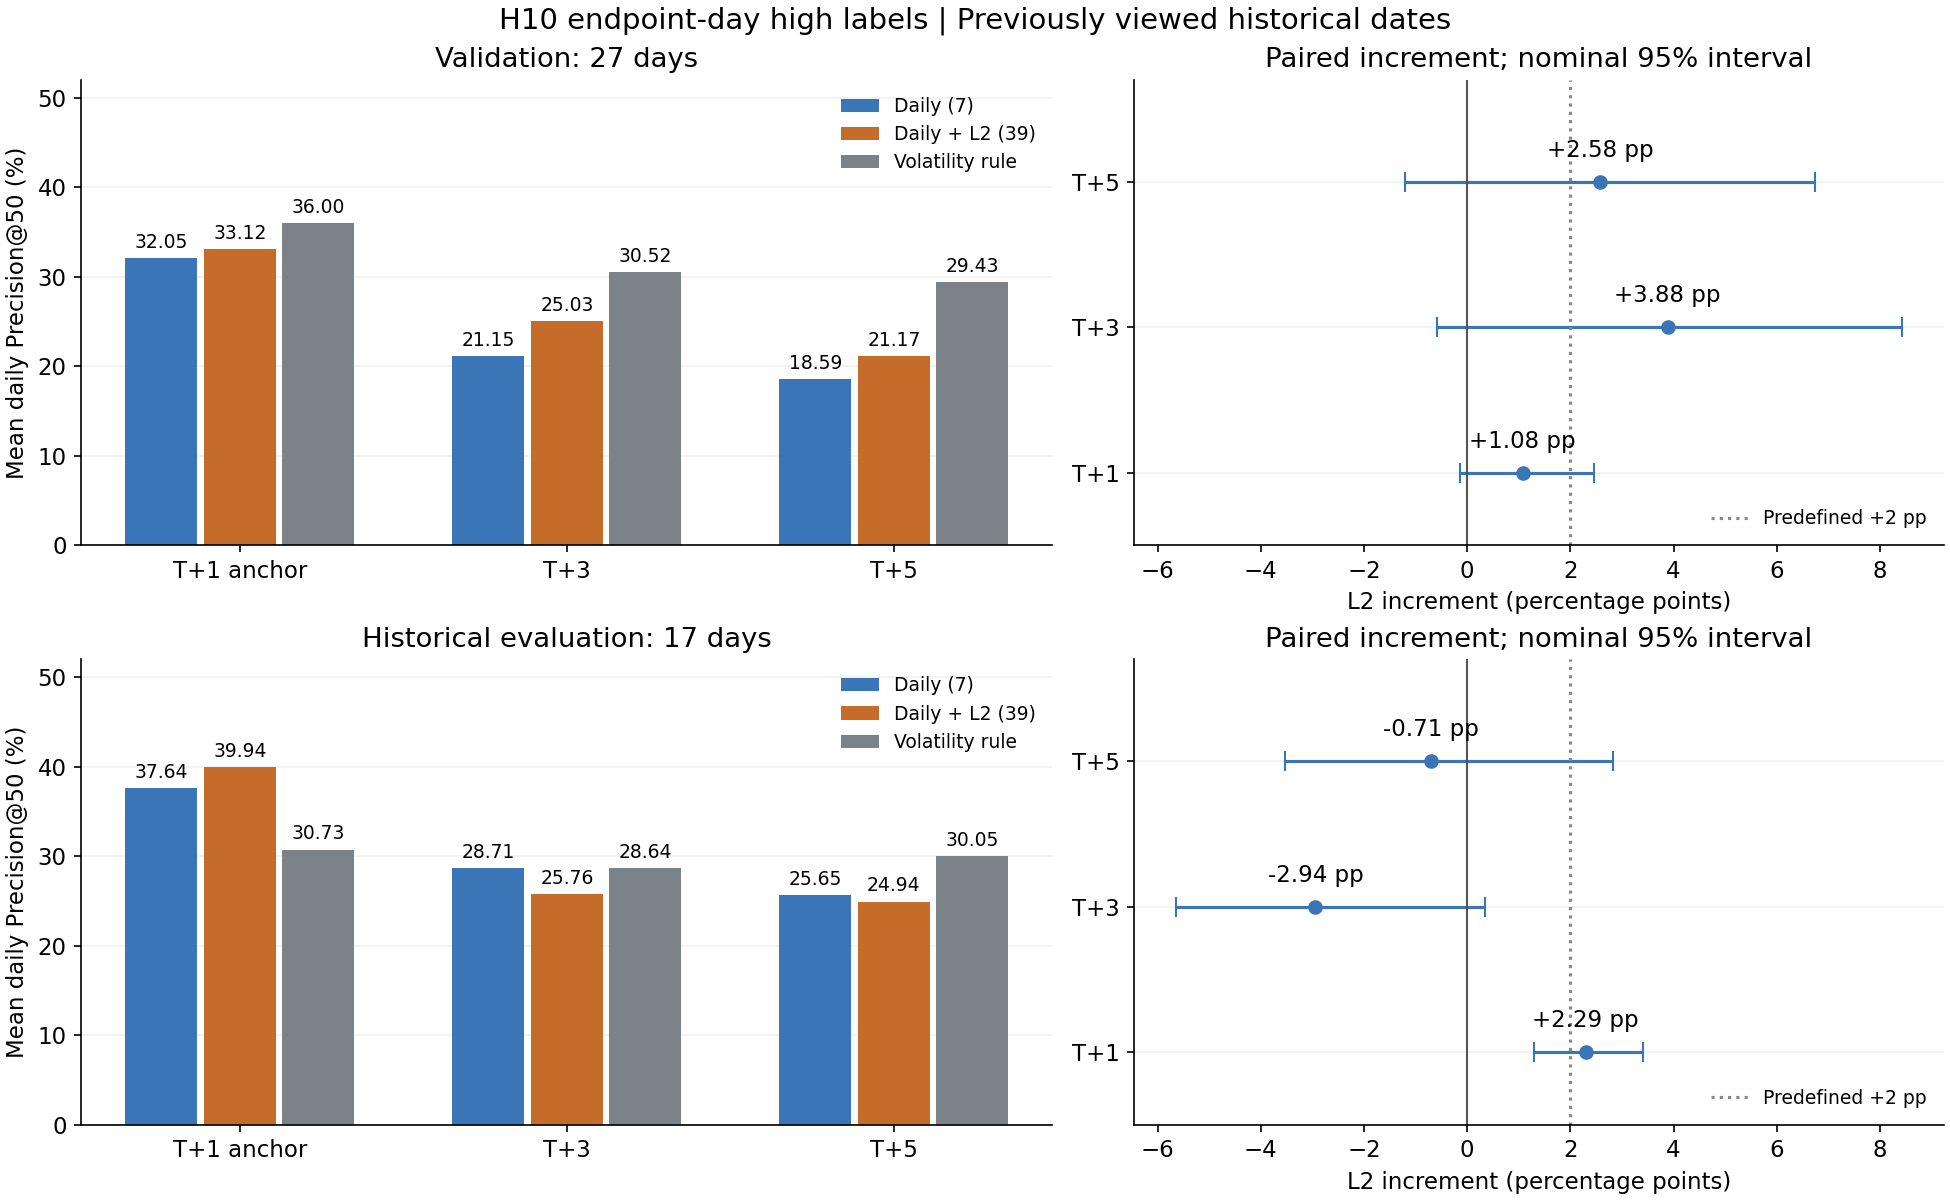

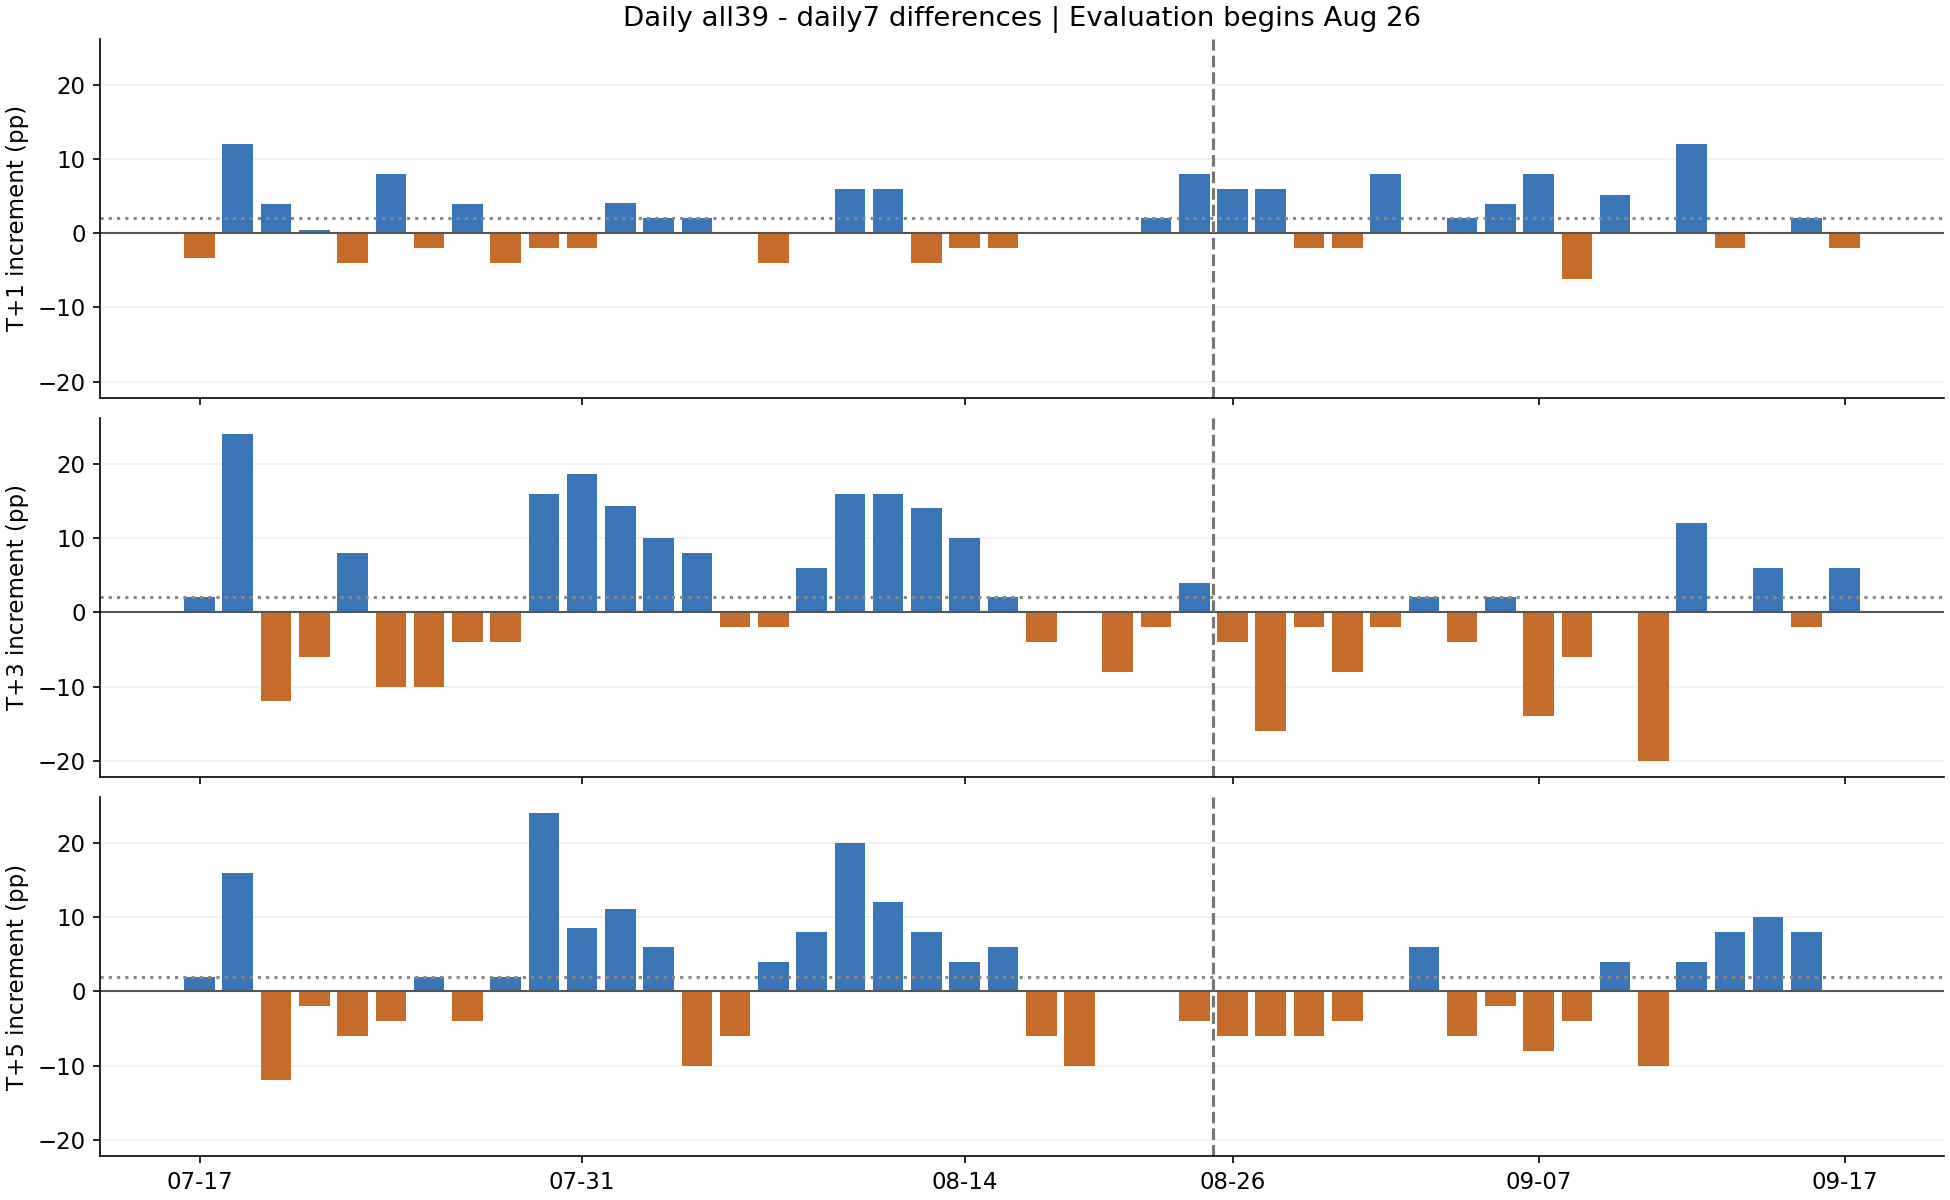

In [8]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
colors = {"daily7": "#3975B7", "all39": "#C66C2B", "rule_volatility": "#7B8389"}
names = {"daily7": "Daily (7)", "all39": "Daily + L2 (39)", "rule_volatility": "Volatility rule"}
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained", gridspec_kw={"width_ratios": [1.2, 1]})
for row, stage in enumerate(["validation", "evaluation"]):
    for offset, method in enumerate(colors):
        values = summary.loc[summary.stage.eq(stage) & summary.method.eq(method)].set_index("horizon").loc[[1, 3, 5], "precision"].to_numpy() * 100
        bars = axes[row, 0].bar(np.arange(3) + (offset - 1) * 0.24, values, width=0.22, color=colors[method], label=names[method])
        axes[row, 0].bar_label(bars, fmt="%.2f", fontsize=9, padding=3)
    axes[row, 0].set_xticks(np.arange(3), ["T+1 anchor", "T+3", "T+5"])
    axes[row, 0].set_ylim(0, 52)
    axes[row, 0].set_ylabel("Mean daily Precision@50 (%)")
    axes[row, 0].set_title("Validation: 27 days" if stage == "validation" else "Historical evaluation: 17 days")
    axes[row, 0].legend(frameon=False, fontsize=9, loc="upper right")
    part = comparison.loc[comparison.stage.eq(stage)].set_index("horizon").loc[[1, 3, 5]]
    means = part.mean_difference.to_numpy() * 100
    lower = part.ci95_lower.to_numpy() * 100
    upper = part.ci95_upper.to_numpy() * 100
    axes[row, 1].errorbar(means, np.arange(3), xerr=np.vstack([means - lower, upper - means]), fmt="o", capsize=5, color="#3975B7")
    for position, value in enumerate(means):
        axes[row, 1].annotate(f"{value:+.2f} pp", (value, position), xytext=(0, 12), textcoords="offset points", ha="center")
    axes[row, 1].axvline(0, color="#555555", linewidth=1)
    axes[row, 1].axvline(2, color="#888888", linestyle=":", label="Predefined +2 pp")
    axes[row, 1].set_yticks(np.arange(3), ["T+1", "T+3", "T+5"])
    axes[row, 1].set_ylim(-0.5, 2.7)
    axes[row, 1].set_xlim(comparison.ci95_lower.min() * 100 - 0.8, comparison.ci95_upper.max() * 100 + 0.8)
    axes[row, 1].set_xlabel("L2 increment (percentage points)")
    axes[row, 1].set_title("Paired increment; nominal 95% interval")
    axes[row, 1].legend(frameon=False, fontsize=9, loc="lower right")
for axis in axes.flat:
    axis.grid(axis="y", alpha=0.18)
    axis.set_axisbelow(True)
fig.suptitle("H10 endpoint-day high labels | Previously viewed historical dates", fontsize=14)
fig.savefig(evidence / "figures/horizon-comparison.png", dpi=150)
plt.close(fig)
display(Image(filename=str(evidence / "figures/horizon-comparison.png")))

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True, sharey=True, layout="constrained")
for axis, horizon in zip(axes, [1, 3, 5]):
    values = pd.concat([paired.xs((horizon, stage)) for stage in ["validation", "evaluation"]])
    difference = values.difference.to_numpy() * 100
    axis.bar(np.arange(44), difference, color=np.where(difference >= 0, "#3975B7", "#C66C2B"))
    axis.axhline(0, color="#555555", linewidth=1)
    axis.axhline(2, color="#888888", linestyle=":")
    axis.axvline(26.5, color="#777777", linestyle="--")
    axis.set_ylabel(f"T+{horizon} increment (pp)")
    axis.grid(axis="y", alpha=0.18)
    axis.set_axisbelow(True)
ticks = [0, 10, 20, 27, 35, 43]
axes[-1].set_xticks(ticks, [protocol["prediction_dates"][i][5:] for i in ticks])
axes[0].set_title("Daily all39 - daily7 differences | Evaluation begins Aug 26")
fig.savefig(evidence / "figures/horizon-daily-increment.png", dpi=150)
plt.close(fig)
display(Image(filename=str(evidence / "figures/horizon-daily-increment.png")))


## 9. 重载、证据守恒与复跑

重载六个模型恢复全部预测，核对输入和源码未变、T+1锚点、所有方法日数量和未知标签。
输出只写隔离证据目录，没有调用API、正式数据发布、provider或broker。

精确复跑应复制此证据目录到新目录，保留其输入、源码和protocol原文，修改首个代码单元的
`evidence`路径；使用保存的依赖版本及项目Python 3.13，从头顺序执行。不要覆盖本次证据。
当前Notebook使用项目IPython内核；执行器在证据目录的`execute_notebook.py`，会保留技术失败。
图表只解释预测事件和名义不确定性；模型不构成实盘采用，退出行为与净收益不在本轮范围。

首轮连接改变symbol类型的准备失败发生在拟合前，保留于`failed-attempt-01/`；修复后保持键和全部验收断言不变。图表首次检查后只移动图例、统一增量坐标轴，不重训或改指标。

展示验证：两张PNG均已实际查看，已修复图例与数值遮挡并统一增量横轴。HTML导出及嵌入输出检查通过；本机无浏览器可执行文件，未做整页浏览器截图检查。可在浏览器打开同目录的`horizon_comparison.html`检查整页排版。


In [9]:
replayed_rows = 0
for record in fit_records:
    horizon, method = record["horizon"], record["method"]
    path = evidence / "models" / f"t{horizon}-{method}.joblib"
    assert hashlib.sha256(path.read_bytes()).hexdigest() == record["model_sha256"]
    restored = joblib.load(path)
    reproduced = restored.predict(prediction_features[record["feature_columns"]].to_numpy(dtype=float))
    saved = pd.read_parquet(evidence / "predictions" / f"t{horizon}-{method}.parquet")
    assert saved[keys].equals(prediction_features[keys])
    np.testing.assert_array_equal(reproduced, saved.prediction)
    replayed_rows += len(saved)
for record in input_manifest:
    assert hashlib.sha256((evidence / record["path"]).read_bytes()).hexdigest() == record["sha256"], record["path"]
for relative, record in source_manifest.items():
    assert hashlib.sha256((evidence / "runtime-source" / relative).read_bytes()).hexdigest() == record["sha256"], relative
assert hashlib.sha256(pd.util.hash_pandas_object(features, index=True).to_numpy().tobytes()).hexdigest() == feature_digest
assert replayed_rows == 1319910 and label_anchor_days == 151 and independent_method_days == 924
verification = {"protocol_sha256": hashlib.sha256((evidence / "protocol.json").read_bytes()).hexdigest(),
                "source_commit": protocol["base_commit"], "input_files": len(input_manifest), "source_files": len(source_manifest),
                "inputs_unchanged": True, "feature_digest": feature_digest, "t1_label_days_exact": label_anchor_days,
                "t1_anchor_prediction_rows_exact": anchor_prediction_rows, "independently_recomputed_method_days": independent_method_days,
                "models_fitted": len(fit_records), "models_reloaded": len(fit_records), "replayed_prediction_rows": replayed_rows,
                "unknown_labels_do_not_change_selection": True, "maturity_boundaries_verified": True, "evaluation_labels_do_not_change_fit_rows_or_targets": True,
                "new_independent_validation_dates": 0, "production_writes": False,
                "nominal_both_periods": comparison.groupby("horizon").nominal_criterion_met.all().to_dict(),
                "adjusted_both_periods": comparison.groupby("horizon").adjusted_criterion_met.all().to_dict()}
(evidence / "verification.json").write_text(json.dumps(verification, ensure_ascii=False, indent=2))
print(json.dumps(verification, ensure_ascii=False, indent=2))


{
  "protocol_sha256": "6c79f05539bd3993399d55c90f7e7e9688929df371e5b75cce80c339de25ff97",
  "source_commit": "76c25a279685b6961cda69143f542e8ec3936f51",
  "input_files": 1047,
  "source_files": 169,
  "inputs_unchanged": true,
  "feature_digest": "9086fe2e6ba6476c2a3c22a49c3c654bea4e797e9b763d71774120262bd2b13e",
  "t1_label_days_exact": 151,
  "t1_anchor_prediction_rows_exact": 439970,
  "independently_recomputed_method_days": 924,
  "models_fitted": 6,
  "models_reloaded": 6,
  "replayed_prediction_rows": 1319910,
  "unknown_labels_do_not_change_selection": true,
  "maturity_boundaries_verified": true,
  "evaluation_labels_do_not_change_fit_rows_or_targets": true,
  "new_independent_validation_dates": 0,
  "production_writes": false,
  "nominal_both_periods": {
    "1": false,
    "3": false,
    "5": false
  },
  "adjusted_both_periods": {
    "1": false,
    "3": false,
    "5": false
  }
}
